In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

iris = load_iris(as_frame=True)
df = iris.data                       # 4 features, no labels used for clustering
true_labels = iris.target            # only kept to check our result at the end

X = StandardScaler().fit_transform(df)
print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


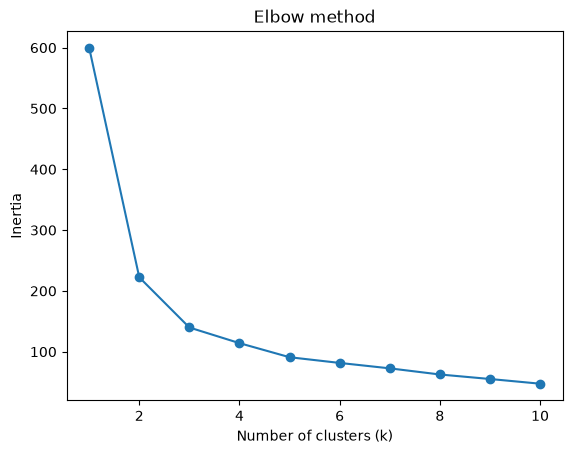

In [2]:
from sklearn.cluster import KMeans

inertia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    inertia.append(km.inertia_)

plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow method")
plt.show()

In [3]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
km_labels = kmeans.fit_predict(X)

df_result = df.copy()
df_result["KMeans_cluster"] = km_labels
print(df_result["KMeans_cluster"].value_counts())

KMeans_cluster
0    53
1    50
2    47
Name: count, dtype: int64


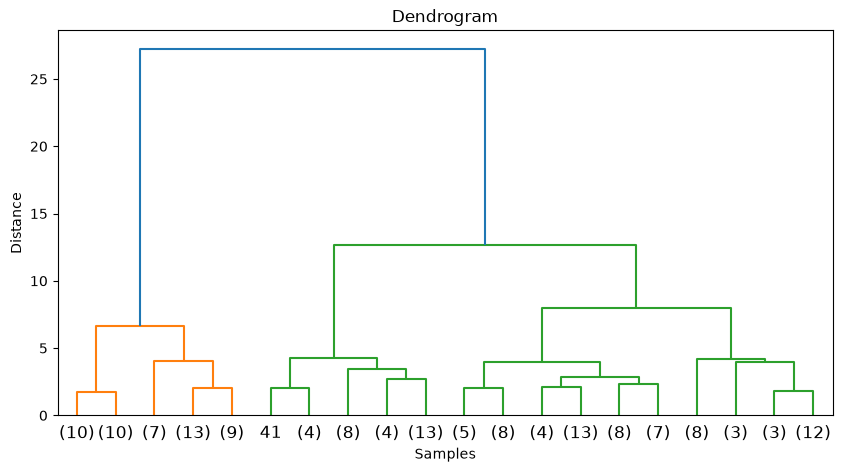

In [4]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X, method="ward")

plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode="lastp", p=20)
plt.title("Dendrogram")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.show()

In [5]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(n_clusters=3, linkage="ward")
hc_labels = hc.fit_predict(X)

df_result["Hierarchical_cluster"] = hc_labels
print(df_result["Hierarchical_cluster"].value_counts())

Hierarchical_cluster
0    71
1    49
2    30
Name: count, dtype: int64


In [6]:
print("Average of each feature in every K-Means cluster:")
print(df_result.groupby("KMeans_cluster")[list(df.columns)].mean().round(2))

Average of each feature in every K-Means cluster:
                sepal length (cm)  sepal width (cm)  petal length (cm)  \
KMeans_cluster                                                           
0                            5.80              2.67               4.37   
1                            5.01              3.43               1.46   
2                            6.78              3.10               5.51   

                petal width (cm)  
KMeans_cluster                    
0                           1.41  
1                           0.25  
2                           1.97  


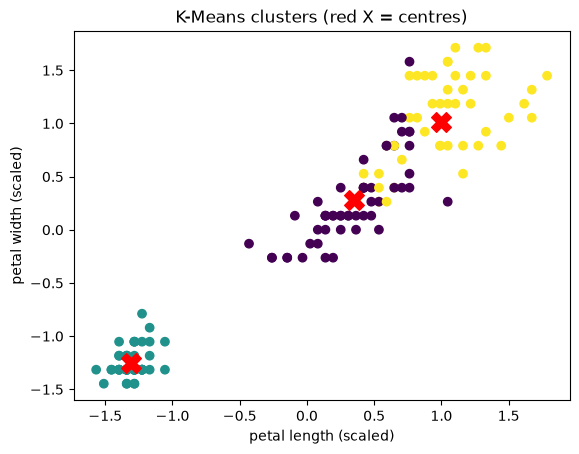

In [7]:
plt.scatter(X[:, 2], X[:, 3], c=km_labels)
plt.scatter(kmeans.cluster_centers_[:, 2], kmeans.cluster_centers_[:, 3], c="red", marker="X", s=200)
plt.xlabel("petal length (scaled)")
plt.ylabel("petal width (scaled)")
plt.title("K-Means clusters (red X = centres)")
plt.show()

In [8]:
# How well do the clusters match the real species?
print(pd.crosstab(true_labels, km_labels, rownames=["Species"], colnames=["KMeans cluster"]))

KMeans cluster   0   1   2
Species                   
0                0  50   0
1               39   0  11
2               14   0  36
